# NatGeo Aquatic Life Tracking + Exporting Pipeline
**YOLO-World + ByteTrack** — processes every `.mp4` in `demo_vids/`.

Optional toggles:
- **CLAHE + White Balance** — improves detection in murky underwater footage
- **Video Compression** — re-encodes inputs to 480p before tracking
- **Black Frame Trimming** — strips leading black frames

### Steps
1. Check GPU
2. Configure paths & flags
3. Install dependencies
4. Color enhancement helpers (optional)
5. Load YOLO-World model
6. Compression & trimming helpers
7. Inspect video dimensions & define counting zone
8. Preview first frame
9. **Run tracking on entire `demo_vids/` folder**
10. Preview result
11. Saving First Bounding Box per Tracked Animal by video

## 1 · Check GPU
Make sure you're on a T4: Runtime → Change runtime type → GPU.

In [1]:
!nvidia-smi

Thu Apr 16 22:07:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2 · Configure Paths & Flags
Edit **this cell only** to change input folder, output folder, and toggle optional features.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path
import sys

# ── Paths (edit these) ────────────────────────────────────────────────────
DRIVE_ROOT          = '/content/drive/My Drive'
VIDEO_INPUT_FOLDER  = os.path.join(DRIVE_ROOT, 'demo_vids')   # source .mp4 files
VIDEO_OUTPUT_FOLDER = os.path.join(DRIVE_ROOT, 'demo_vids', 'output')  # tracked results

os.makedirs(VIDEO_OUTPUT_FOLDER, exist_ok=True)

# ── Optional feature flags ────────────────────────────────────────────────
APPLY_CLAHE    = False   # White balance + CLAHE contrast boost per frame
TRIM_BLACK     = True  # Strip leading black frames

# COMPRESS_VIDEO:
#   False (default) — frames are resized to 480p on-the-fly during tracking.
#                     No extra disk space used; best for a single pass.
#   True            — video is pre-compressed to 480p before tracking starts.
#                     Faster if you plan to run YOLO on the same video multiple times.
COMPRESS_VIDEO = False

# COPY_TO_LOCAL:
#   False (default) — read video frames directly from Google Drive during inference.
#   True            — copy each video to /tmp/ on Colab's local disk first.
#                     Eliminates Drive I/O latency; recommended for large files.
COPY_TO_LOCAL  = True

# USE_FP16:
#   False (default) — standard float32 inference.
#   True            — half-precision inference; ~2× faster on T4 with minimal accuracy loss.
USE_FP16       = False

# FRAME_SKIP:
#   1 (default) — process every frame.
#   3           — process frames 0, 3, 6, 9 … skipping 2 in between.
#                 Speeds up inference proportionally; may reduce tracking continuity.
FRAME_SKIP     = 1

# ── Compression settings (used only when COMPRESS_VIDEO = True) ───────────
COMPRESS_CRF = 23  # 0–51: lower = better quality, larger file (23 = default, 18 ≈ lossless)

# ── Scan input folder ─────────────────────────────────────────────────────
if not os.path.isdir(VIDEO_INPUT_FOLDER):
    print(f'WARNING: Input folder not found: {VIDEO_INPUT_FOLDER}')
    print('Make sure your Drive is mounted and demo_vids/ exists.')
else:
    mp4_files = sorted([
        f for f in os.listdir(VIDEO_INPUT_FOLDER)
        if f.lower().endswith('.mp4')
    ])
    if mp4_files:
        print(f'Found {len(mp4_files)} MP4 file(s) in {VIDEO_INPUT_FOLDER}:')
        for f in mp4_files:
            size_mb = os.path.getsize(os.path.join(VIDEO_INPUT_FOLDER, f)) / (1024**2)
            print(f'  {f}  ({size_mb:.1f} MB)')
    else:
        print(f'No MP4 files found in {VIDEO_INPUT_FOLDER}')
        print('Add your videos to demo_vids/ in Google Drive and re-run this cell.')

print(f'\nInput  : {VIDEO_INPUT_FOLDER}')
print(f'Output : {VIDEO_OUTPUT_FOLDER}')
print(f'Flags  CLAHE={APPLY_CLAHE}  Compress={COMPRESS_VIDEO}  TrimBlack={TRIM_BLACK}  CRF={COMPRESS_CRF}')
print(f'       CopyLocal={COPY_TO_LOCAL}  FP16={USE_FP16}  FrameSkip={FRAME_SKIP}')


Mounted at /content/drive
Found 1 MP4 file(s) in /content/drive/My Drive/demo_vids:
  PLW_dscm_49_c045.mp4  (576.1 MB)

Input  : /content/drive/My Drive/demo_vids
Output : /content/drive/My Drive/demo_vids/output
Flags  CLAHE=False  Compress=False  TrimBlack=True  CRF=23
       CopyLocal=True  FP16=False  FrameSkip=1


## 3 · Install Dependencies

In [3]:
!pip install -q ultralytics supervision>=0.18.0 lapjv
!yolo settings sync=False

from IPython import display as _ipy_display
_ipy_display.clear_output()

import supervision as sv
print('supervision version:', sv.__version__)

supervision version: 0.27.0.post2


## 4 · Imports

In [4]:
import csv
import numpy as np
import cv2
import glob as _glob
import subprocess
import shutil
import time
from tqdm.notebook import tqdm
from ultralytics import YOLOWorld
import supervision as sv
from supervision import VideoInfo, get_video_frames_generator, VideoSink
from supervision import BoxAnnotator, LabelAnnotator
from IPython.display import Image as IPImage, display

## 5 · Color Enhancement Helpers  *(used only when `APPLY_CLAHE = True`)*
- **White balance** — removes the blue-green cast common in underwater footage
- **CLAHE** — boosts local contrast in LAB color space so animals stand out

Set `APPLY_CLAHE = False` in cell 2 to skip both.

In [5]:
def white_balance(frame: np.ndarray) -> np.ndarray:
    """Grey-world white balance — equalises BGR channel means."""
    result = frame.copy().astype(np.float32)
    mb, mg, mr = result[:,:,0].mean(), result[:,:,1].mean(), result[:,:,2].mean()
    mean_all = (mb + mg + mr) / 3.0
    if mb > 1: result[:,:,0] *= mean_all / mb
    if mg > 1: result[:,:,1] *= mean_all / mg
    if mr > 1: result[:,:,2] *= mean_all / mr
    return np.clip(result, 0, 255).astype(np.uint8)


_clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))   # 32, 32

def apply_clahe(frame: np.ndarray) -> np.ndarray:
    """CLAHE on the L channel of LAB — boosts local contrast."""
    lab = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = _clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)


def enhance_frame(frame: np.ndarray) -> np.ndarray:
    """White balance → CLAHE pipeline."""
    return apply_clahe(white_balance(frame))


print('Color enhancement helpers loaded.')
print(f'Will be applied: {APPLY_CLAHE}')

Color enhancement helpers loaded.
Will be applied: False


## 6 · Load YOLO-World Model
Open-vocabulary detector — add/remove species from `AQUATIC_CLASSES` to change what gets detected.

In [10]:

# ── Load fine-tuned model ──────────────────────────────────────────────────
import os, shutil

FINETUNED_MODEL = 'yolov8x-worldv2-fish-ft.pt'

# 1) Already in the working directory
if os.path.exists(FINETUNED_MODEL):
    print(f"✓ '{FINETUNED_MODEL}' already present in working directory.")

# 2) Copy from Google Drive (fastest for large .pt files — no browser widget needed)
else:
    DRIVE_MODEL_PATH = os.path.join(DRIVE_ROOT, FINETUNED_MODEL)
    if os.path.exists(DRIVE_MODEL_PATH):
        print(f"Copying from Drive: {DRIVE_MODEL_PATH} …")
        shutil.copy(DRIVE_MODEL_PATH, FINETUNED_MODEL)
        print(f"✓ Copied {FINETUNED_MODEL} from Drive.")

    # 3) Fall back to browser upload (requires active browser session)
    else:
        from google.colab import files
        print(f"'{FINETUNED_MODEL}' not found in working directory or Drive.")
        print(f"Expected Drive path: {DRIVE_MODEL_PATH}")
        print("Falling back to browser upload — upload the .pt file below:")
        uploaded = files.upload()
        if FINETUNED_MODEL in uploaded:
            print(f"✓ Uploaded {FINETUNED_MODEL}")
        else:
            print("No fine-tuned model uploaded — will fall back to base model in next cell.")


'yolov8x-worldv2-fish-ft.pt' not found in working directory or Drive.
Expected Drive path: /content/drive/My Drive/yolov8x-worldv2-fish-ft.pt
Falling back to browser upload — upload the .pt file below:


KeyboardInterrupt: 

In [ ]:

import os

FINETUNED_MODEL = 'yolov8x-worldv2-fish-ft.pt'
BASE_MODEL      = 'yolov8x-worldv2.pt'

if os.path.exists(FINETUNED_MODEL):
    MODEL = FINETUNED_MODEL
    print(f"Loading fine-tuned model: {MODEL}")
else:
    MODEL = BASE_MODEL
    print(f"Fine-tuned model not found — falling back to base model: {MODEL}")

model = YOLOWorld(MODEL)

AQUATIC_CLASSES = [
    'fish', 'crab', 'shrimp', 'lobster', 'octopus',
    'squid', 'jellyfish', 'sea turtle', 'eel',
    'starfish', 'ray', 'shark',
]

model.set_classes(AQUATIC_CLASSES)
print('Tracking classes:', AQUATIC_CLASSES)
if USE_FP16:
    print('FP16 enabled — will pass half=True at inference time')


## 7 · Video Helpers — Compression & Frame Extraction
- **`resize_video`** — re-encodes a single video to 480p (auto-picks NVENC → VAAPI → CPU). Audio is stripped; not needed for CV.
- **`extract_frames`** — pulls frames to disk as JPEGs at any target fps (useful for offline inspection).
- **`batch_resize`** — convenience wrapper that resizes every video in a folder.

Toggle compression via `COMPRESS_VIDEO` and quality via `COMPRESS_CRF` in cell 2.

In [26]:
import subprocess
import sys
import threading
from pathlib import Path

TARGET_WIDTH  = 854
TARGET_HEIGHT = 480
VIDEO_EXTENSIONS = {'.mp4', '.mov', '.mkv', '.avi', '.webm', '.m4v', '.mts', '.ts'}


def detect_encoder() -> tuple[str, list[str]]:
    """Probe for NVENC (GPU) → VAAPI (GPU) → libx264 (CPU), return first that works."""
    probes = [
        ('h264_nvenc', ['-hwaccel', 'cuda', '-hwaccel_output_format', 'cuda']),
        ('h264_vaapi', ['-hwaccel', 'vaapi', '-vaapi_device', '/dev/dri/renderD128']),
    ]
    null = subprocess.DEVNULL
    for enc, hw_flags in probes:
        probe_cmd = [
            'ffmpeg', '-y', '-f', 'lavfi', '-i', 'testsrc=duration=1:size=3840x2160',
            *hw_flags, '-vframes', '1', '-c:v', enc, '-f', 'null', '-',
        ]
        if subprocess.run(probe_cmd, stdout=null, stderr=null).returncode == 0:
            return enc, hw_flags
    return 'libx264', []


def _build_scale_filter(encoder: str) -> str:
    """Return the vf scale filter string appropriate for the given encoder."""
    pad = f'pad={TARGET_WIDTH}:{TARGET_HEIGHT}:(ow-iw)/2:(oh-ih)/2'
    if 'vaapi' in encoder:
        return f'scale_vaapi=w={TARGET_WIDTH}:h={TARGET_HEIGHT}:force_original_aspect_ratio=decrease,{pad}'
    elif 'nvenc' in encoder:
        return f'scale_cuda={TARGET_WIDTH}:{TARGET_HEIGHT}:force_original_aspect_ratio=decrease,hwdownload,format=nv12'
    else:
        return f'scale={TARGET_WIDTH}:{TARGET_HEIGHT}:force_original_aspect_ratio=decrease,{pad},format=yuv420p'


def _get_frame_count(path: Path) -> int:
    """Return total frame count via ffprobe, or 0 if unavailable."""
    r = subprocess.run(
        ['ffprobe', '-v', 'error', '-select_streams', 'v:0',
         '-count_packets', '-show_entries', 'stream=nb_read_packets',
         '-of', 'csv=p=0', str(path)],
        capture_output=True, text=True,
    )
    val = r.stdout.strip()
    return int(val) if val.isdigit() else 0


def resize_video(input_path, output_path, crf=23, encoder=None, hw_flags=None, force_cpu=False) -> bool:
    """
    Resize a video to 480p and re-encode it with a live tqdm progress bar.
    Auto-detects the fastest available encoder (NVENC > VAAPI > CPU).
    Audio is stripped — not needed for CV pipelines.
    """
    input_path  = Path(input_path)
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    if encoder is None:
        if force_cpu:
            encoder, hw_flags = 'libx264', []
        else:
            encoder, hw_flags = detect_encoder()

    hw_flags = hw_flags or []
    vf    = _build_scale_filter(encoder)
    extra = []
    if encoder == 'libx264':      extra = ['-crf', str(crf), '-preset', 'fast']
    elif encoder == 'h264_nvenc': extra = ['-cq',  str(crf), '-preset', 'p4']
    elif encoder == 'h264_vaapi': extra = ['-qp',  str(crf)]

    total_frames = _get_frame_count(input_path)

    cmd = [
        'ffmpeg', '-y', *hw_flags,
        '-i', str(input_path),
        '-vf', vf, '-c:v', encoder, *extra,
        '-an', '-movflags', '+faststart',
        '-progress', 'pipe:1', '-nostats',
        str(output_path),
    ]

    process = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

    # Drain stderr on a background thread to prevent buffer deadlock
    stderr_buf = []
    threading.Thread(
        target=lambda: stderr_buf.extend(process.stderr.readlines()), daemon=True
    ).start()

    with tqdm(total=total_frames or None, desc=f'  Compressing {input_path.name}',
              unit='frame', leave=True) as pbar:
        last = 0
        for line in process.stdout:
            if line.startswith('frame='):
                val = line.split('=')[1].strip()
                if val.isdigit():
                    current = int(val)
                    pbar.update(current - last)
                    last = current
        process.wait()

    if process.returncode != 0:
        print(f'  FFmpeg error ({input_path.name}):\n' + ''.join(stderr_buf[-20:]), file=sys.stderr)
        return False

    in_mb  = input_path.stat().st_size  / (1024 ** 2)
    out_mb = output_path.stat().st_size / (1024 ** 2)
    print(f'  {in_mb:.1f} MB → {out_mb:.1f} MB ({(1 - out_mb / in_mb) * 100:.1f}% smaller)')
    return True


def extract_frames(input_path, output_dir, fps=None, fmt='jpg', quality=95) -> bool:
    """
    Extract frames from a video at 480p.

    fps     : float | None — frames per second to extract.
              None = every frame. 1 = 1 fps. 0.5 = one frame every 2 sec.
    fmt     : 'jpg' or 'png'
    quality : JPEG quality 1–100 (ignored for PNG)

    Frames are saved as frame_000001.jpg, frame_000002.jpg, …
    """
    input_path = Path(input_path)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    vf = (
        f'scale={TARGET_WIDTH}:{TARGET_HEIGHT}:force_original_aspect_ratio=decrease,'
        f'pad={TARGET_WIDTH}:{TARGET_HEIGHT}:(ow-iw)/2:(oh-ih)/2,format=rgb24'
    )
    if fps is not None:
        vf = f'fps={fps},' + vf

    pattern = str(output_dir / f'frame_%06d.{fmt}')
    extra   = ['-q:v', str(max(1, int((100 - quality) / 100 * 31 + 1)))] if fmt == 'jpg' else []

    cmd = ['ffmpeg', '-y', '-i', str(input_path), '-vf', vf, *extra, pattern]
    fps_label = f'{fps} fps' if fps else 'every frame'
    print(f'Extracting frames ({fps_label}) from {input_path.name} to {output_dir}/')
    result = subprocess.run(cmd, stderr=subprocess.PIPE, text=True)
    if result.returncode != 0:
        print('FFmpeg error:\n' + result.stderr, file=sys.stderr)
        return False
    n = len(list(output_dir.glob(f'*.{fmt}')))
    print(f'Extracted {n:,} frames → {output_dir}/')
    return True


def batch_resize(input_dir, output_dir, crf=23, force_cpu=False) -> tuple[int, int]:
    """
    Resize every video in input_dir to 480p and write results to output_dir.
    Returns (succeeded, total).
    """
    input_dir  = Path(input_dir)
    output_dir = Path(output_dir)
    videos = sorted(f for f in input_dir.iterdir() if f.suffix.lower() in VIDEO_EXTENSIONS)
    if not videos:
        print(f'No video files found in {input_dir}')
        return 0, 0

    print(f'Found {len(videos)} video(s)')
    encoder, hw_flags = ('libx264', []) if force_cpu else detect_encoder()
    print(f'Using: {encoder}\n')

    ok = 0
    for i, v in enumerate(videos, 1):
        print(f'[{i}/{len(videos)}] {v.name}')
        if resize_video(v, output_dir / v.name, crf=crf, encoder=encoder, hw_flags=hw_flags):
            ok += 1
    print(f'\nDone: {ok}/{len(videos)} succeeded')
    return ok, len(videos)


def trim_black_leader(input_path, output_path, threshold=10, max_scan_sec=30) -> bool:
    """
    Strip leading black frames from a video.
    Scans up to max_scan_sec seconds to find the first non-black frame,
    then uses ffmpeg to trim from that timestamp onward.
    threshold: mean pixel brightness (0–255) below which a frame is considered black.
    Audio is stripped — pcm_s16be and similar codecs are not valid in MP4.
    """
    input_path  = Path(input_path)
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    cap = cv2.VideoCapture(str(input_path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    max_frames = int(max_scan_sec * fps)
    start_sec = 0.0

    for i in range(max_frames):
        ret, frame = cap.read()
        if not ret:
            break
        if frame.mean() > threshold:
            start_sec = i / fps
            break
    cap.release()

    cmd = [
        'ffmpeg', '-y', '-ss', f'{start_sec:.3f}',
        '-i', str(input_path),
        '-c:v', 'copy',   # copy video stream (no re-encode)
        '-an',             # drop audio — avoids pcm_s16be/MP4 incompatibility
        str(output_path),
    ]
    result = subprocess.run(cmd, stdout=subprocess.DEVNULL, stderr=subprocess.PIPE)
    if result.returncode != 0:
        print(f'  FFmpeg trim error: {result.stderr.decode()[-500:]}', file=sys.stderr)
        return False

    print(f'  Trimmed {start_sec:.2f}s of black leader → {output_path.name}')
    return True


print('Video helpers loaded.')
print('  resize_video | extract_frames | batch_resize | detect_encoder | trim_black_leader')


Video helpers loaded.
  resize_video | extract_frames | batch_resize | detect_encoder | trim_black_leader


## 7 · Pre-process Videos, Inspect Dimensions & Define Counting Zone
Compresses and trims each video sequentially before tracking — progress bar shown per video.
Processed files are stored in `PROCESSED_VIDEOS`. Re-run after uploading new videos.

In [27]:
mp4_files = sorted(_glob.glob(os.path.join(VIDEO_INPUT_FOLDER, '*.mp4')))
if not mp4_files:
    raise FileNotFoundError(f'No .mp4 files found in {VIDEO_INPUT_FOLDER}')

print(f'Pre-processing {len(mp4_files)} video(s)  '
      f'[Compress={COMPRESS_VIDEO}  TrimBlack={TRIM_BLACK}  CopyLocal={COPY_TO_LOCAL}  CRF={COMPRESS_CRF}]\n')

_encoder, _hw_flags = detect_encoder() if COMPRESS_VIDEO else (None, [])
if COMPRESS_VIDEO:
    print(f'Encoder: {_encoder}\n')

# Dict mapping stem → ready-to-track path
PROCESSED_VIDEOS = {}

for i, video_path in enumerate(mp4_files, 1):
    stem         = Path(video_path).stem
    working_path = video_path
    tmp_files    = []
    print(f'[{i}/{len(mp4_files)}] {stem}')

    if COMPRESS_VIDEO:
        compressed = os.path.join(VIDEO_OUTPUT_FOLDER, f'{stem}_480p.mp4')
        success = resize_video(
            working_path, compressed,
            crf=COMPRESS_CRF, encoder=_encoder, hw_flags=_hw_flags,
        )
        if success:
            working_path = compressed
            tmp_files.append(compressed)
        else:
            print('  Compression failed — using original.')

    if TRIM_BLACK:
        trimmed = os.path.join(VIDEO_OUTPUT_FOLDER, f'{stem}_trimmed.mp4')
        print('  Trimming black frames...')
        success = trim_black_leader(working_path, trimmed)
        if success:
            for f in tmp_files:
                if os.path.exists(f):
                    os.remove(f)
            working_path = trimmed
        else:
            print('  Trim failed — using previous path.')

    if COPY_TO_LOCAL:
        local_path = f'/tmp/{stem}.mp4'
        size_mb = os.path.getsize(working_path) / (1024 ** 2)
        print(f'  Copying to local disk ({size_mb:.1f} MB)...')
        shutil.copy2(working_path, local_path)
        working_path = local_path
        print(f'  Copied → {local_path}')

    PROCESSED_VIDEOS[stem] = working_path
    vi = VideoInfo.from_video_path(working_path)
    print(f'  Ready: {vi.width}x{vi.height} @ {vi.fps}fps | '
          f'{vi.total_frames} frames → {os.path.basename(working_path)}\n')

# ── Use first processed video for dimensions & zone ───────────────────────
first_stem = Path(mp4_files[0]).stem
video_info = VideoInfo.from_video_path(PROCESSED_VIDEOS[first_stem])
W, H = video_info.width, video_info.height

MARGIN  = int(min(W, H) * 0.03)
OPACITY = 0.08

BORDER_POLYGON = np.array([
    [MARGIN,     MARGIN    ],
    [W - MARGIN, MARGIN    ],
    [W - MARGIN, H - MARGIN],
    [MARGIN,     H - MARGIN],
])

print(f'Reference dims: {W}x{H} @ {video_info.fps}fps')
print(f'Border zone margin: {MARGIN}px  |  opacity: {OPACITY}')
print(f'\nAll {len(PROCESSED_VIDEOS)} videos pre-processed. Run step 9 to preview, then step 10 to track.')


Pre-processing 1 video(s)  [Compress=False  TrimBlack=True  CopyLocal=True  CRF=23]

[1/1] PLW_dscm_49_c045
  Trimming black frames...
  Trimmed 3.54s of black leader → PLW_dscm_49_c045_trimmed.mp4
  Copying to local disk (533.9 MB)...
  Copied → /tmp/PLW_dscm_49_c045.mp4
  Ready: 3840x2160 @ 29fps | 1425 frames → PLW_dscm_49_c045.mp4

Reference dims: 3840x2160 @ 29fps
Border zone margin: 64px  |  opacity: 0.08

All 1 videos pre-processed. Run step 9 to preview, then step 10 to track.


## 9 · Preview First Frame
Verify detections and zone position before running the full folder.

Previewing: PLW_dscm_49_c045.mp4


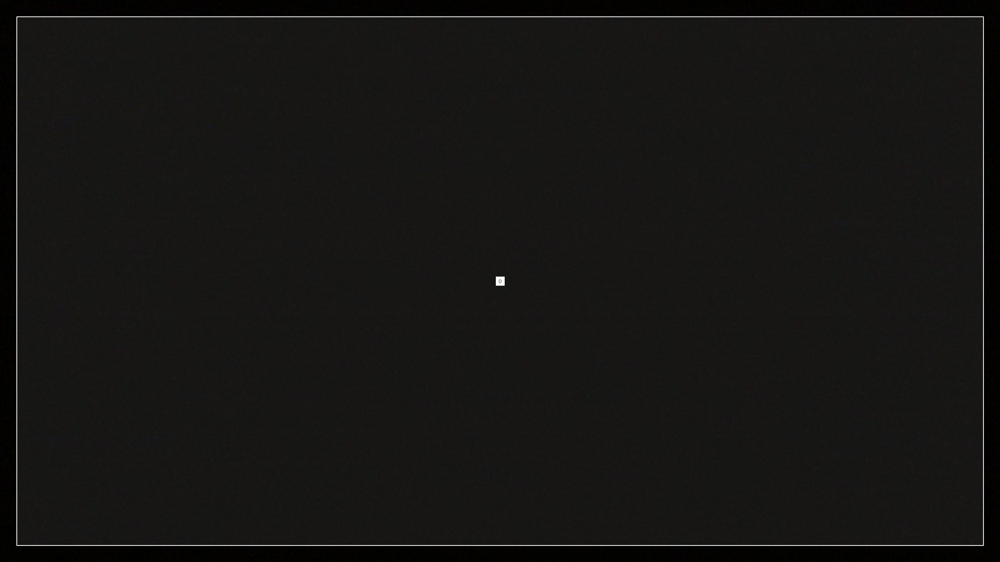

Detected 0 aquatic animals in first frame
CLAHE applied: False


In [28]:
mp4_files = sorted(_glob.glob(os.path.join(VIDEO_INPUT_FOLDER, '*.mp4')))
if not mp4_files:
    raise FileNotFoundError(f'No .mp4 files found in {VIDEO_INPUT_FOLDER}')

preview_path = mp4_files[0]
print(f'Previewing: {os.path.basename(preview_path)}')

gen   = get_video_frames_generator(preview_path)
frame = next(iter(gen))

# Optionally enhance before inference
inference_frame = enhance_frame(frame.copy()) if APPLY_CLAHE else frame.copy()

results    = model(inference_frame, verbose=False)[0]
detections = sv.Detections.from_ultralytics(results)

box_annotator     = BoxAnnotator(color=sv.ColorPalette.DEFAULT, thickness=2)
label_annotator   = LabelAnnotator(text_scale=0.5, text_thickness=1)
polygon_zone      = sv.PolygonZone(polygon=BORDER_POLYGON)
polygon_annotator = sv.PolygonZoneAnnotator(
    zone=polygon_zone, color=sv.Color.WHITE,
    thickness=2, text_scale=0.6, opacity=OPACITY,
)

labels = [
    f"{AQUATIC_CLASSES[cid]} {conf:.2f}"
    for cid, conf in zip(detections.class_id, detections.confidence)
]

preview = inference_frame.copy()
preview = box_annotator.annotate(scene=preview, detections=detections)
preview = label_annotator.annotate(scene=preview, detections=detections, labels=labels)
polygon_zone.trigger(detections=detections)
preview = polygon_annotator.annotate(scene=preview)

_, buf = cv2.imencode('.jpg', cv2.cvtColor(preview, cv2.COLOR_RGB2BGR))
display(IPImage(data=buf.tobytes()))
print(f'Detected {len(detections)} aquatic animals in first frame')
print(f'CLAHE applied: {APPLY_CLAHE}')

## 10 · Track & Count — Entire `demo_vids/` Folder
For each `.mp4`:
1. (Optional) Compress to 480p
2. (Optional) Strip leading black frames
3. Run YOLO-World + ByteTrack frame-by-frame
4. Save annotated output to `output/`

In [29]:
import tempfile

mp4_files = sorted(_glob.glob(os.path.join(VIDEO_INPUT_FOLDER, '*.mp4')))
if not mp4_files:
    raise FileNotFoundError(f'No .mp4 files found in {VIDEO_INPUT_FOLDER}')

print(f'Processing {len(mp4_files)} video(s)  '
      f'[CLAHE={APPLY_CLAHE}  Compress={COMPRESS_VIDEO}  TrimBlack={TRIM_BLACK}  '
      f'CopyLocal={COPY_TO_LOCAL}  FP16={USE_FP16}  FrameSkip={FRAME_SKIP}]\n')

for video_path in mp4_files:
    stem        = Path(video_path).stem
    output_path = os.path.join(VIDEO_OUTPUT_FOLDER, f'{stem}_tracked.mp4')
    working_path = PROCESSED_VIDEOS[stem]  # pre-processed in step 7
    csv_path    = os.path.join(VIDEO_OUTPUT_FOLDER, f'{stem}_bboxes.csv')

    print(f'━━━ {stem} ━━━')

    # ── Resolve output dimensions ──────────────────────────────────────────
    # COMPRESS_VIDEO=True  → video is already 480p, use its native dimensions.
    # COMPRESS_VIDEO=False → video may be any resolution; we'll resize on-the-fly
    #                        so tell VideoSink to write at 480p from the start.
    raw_info = VideoInfo.from_video_path(working_path)
    if COMPRESS_VIDEO:
        video_info = raw_info
    else:
        video_info = VideoInfo(
            width=TARGET_WIDTH,
            height=TARGET_HEIGHT,
            fps=raw_info.fps,
            total_frames=raw_info.total_frames,
        )

    W, H = video_info.width, video_info.height
    tracked_frames = (video_info.total_frames + FRAME_SKIP - 1) // FRAME_SKIP
    print(f'  {raw_info.width}x{raw_info.height} → {W}x{H} @ {video_info.fps}fps  |  '
          f'{video_info.total_frames} frames  |  inferring {tracked_frames} (every {FRAME_SKIP})')

    # Recalculate zone for output dimensions
    margin = int(min(W, H) * 0.03)
    border_polygon = np.array([
        [margin,     margin    ],
        [W - margin, margin    ],
        [W - margin, H - margin],
        [margin,     H - margin],
    ])

    # ByteTrack — frame_rate must match the video for accurate Kalman predictions
    tracker = sv.ByteTrack(frame_rate=int(video_info.fps))

    box_annotator     = BoxAnnotator(color=sv.ColorPalette.DEFAULT, thickness=2)
    label_annotator   = LabelAnnotator(text_scale=0.5, text_thickness=1)
    polygon_zone      = sv.PolygonZone(polygon=border_polygon)
    polygon_annotator = sv.PolygonZoneAnnotator(
        zone=polygon_zone, color=sv.Color.WHITE,
        thickness=2, text_scale=0.6, opacity=OPACITY,
    )

    all_tracker_ids = set()

    # ── Main tracking loop ────────────────────────────────────────────────
    with VideoSink(output_path, video_info) as sink, \
         open(csv_path, "w", newline="") as csv_file:

        writer = csv.writer(csv_file)
        writer.writerow(["video", "frame", "tracker_id", "class", "confidence",
                          "x1", "y1", "x2", "y2"])

        for iter_idx, frame in enumerate(tqdm(
            get_video_frames_generator(working_path, stride=FRAME_SKIP),
            total=tracked_frames,
            desc=f'  Tracking',
            leave=True,
        )):
            frame_idx = iter_idx * FRAME_SKIP  # actual frame number in the source video

            # Resize on-the-fly when not pre-compressed
            if not COMPRESS_VIDEO:
                frame = cv2.resize(frame, (TARGET_WIDTH, TARGET_HEIGHT))

            # Optionally enhance frame before inference
            inference_frame = enhance_frame(frame.copy()) if APPLY_CLAHE else frame.copy()

            # half=USE_FP16 lets ultralytics handle FP16 conversion safely internally
            results    = model(inference_frame, verbose=False, half=USE_FP16)[0]
            detections = sv.Detections.from_ultralytics(results)
            detections = tracker.update_with_detections(detections)

            if detections.tracker_id is not None:
                all_tracker_ids.update(detections.tracker_id.tolist())

                # ── Write bounding boxes to CSV ───────────────────────────
                for tid, cid, conf, bbox in zip(
                    detections.tracker_id,
                    detections.class_id,
                    detections.confidence,
                    detections.xyxy,
                ):
                    x1, y1, x2, y2 = bbox
                    writer.writerow([
                        stem, frame_idx, int(tid),
                        AQUATIC_CLASSES[cid], f"{conf:.4f}",
                        int(x1), int(y1), int(x2), int(y2),
                    ])

            labels = [
                f"#{tid} {AQUATIC_CLASSES[cid]} {conf:.2f}"
                for tid, cid, conf in zip(
                    detections.tracker_id if detections.tracker_id is not None else [],
                    detections.class_id,
                    detections.confidence,
                )
            ]

            polygon_zone.trigger(detections=detections)

            annotated = inference_frame.copy()
            annotated = box_annotator.annotate(scene=annotated, detections=detections)
            annotated = label_annotator.annotate(scene=annotated, detections=detections, labels=labels)
            annotated = polygon_annotator.annotate(scene=annotated)

            sink.write_frame(annotated)

    print(f'  Unique animals tracked: {len(all_tracker_ids)}')
    print(f'  Saved → {output_path}')
    print(f'  CSV   → {csv_path}\n')


Processing 1 video(s)  [CLAHE=False  Compress=False  TrimBlack=True  CopyLocal=True  FP16=False  FrameSkip=1]

━━━ PLW_dscm_49_c045 ━━━
  3840x2160 → 854x480 @ 29fps  |  1425 frames  |  inferring 1425 (every 1)


  Tracking:   0%|          | 0/1425 [00:00<?, ?it/s]

  Unique animals tracked: 123
  Saved → /content/drive/My Drive/demo_vids/output/PLW_dscm_49_c045_tracked.mp4
  CSV   → /content/drive/My Drive/demo_vids/output/PLW_dscm_49_c045_bboxes.csv



## 11 · Preview Last Result in Notebook

In [30]:
from IPython.display import HTML
from base64 import b64encode

output_files = sorted(_glob.glob(os.path.join(VIDEO_OUTPUT_FOLDER, '*_tracked.mp4')))
if not output_files:
    print('No tracked output files found yet — run step 10 first.')
else:
    preview_output = output_files[-1]
    print(f'Previewing: {os.path.basename(preview_output)}')

    # Re-encode to H.264 for browser compatibility (mp4v is not browser-safe)
    h264_path = preview_output.replace('_tracked.mp4', '_preview.mp4')
    subprocess.run(
        ['ffmpeg', '-y', '-i', preview_output,
         '-vcodec', 'libx264', '-crf', '23', '-pix_fmt', 'yuv420p', h264_path],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )

    mp4  = open(h264_path, 'rb').read()
    data = b64encode(mp4).decode()
    display(HTML(f'<video width=854 controls>'
                 f'<source src="data:video/mp4;base64,{data}" type="video/mp4">'
                 f'</video>'))

Previewing: PLW_dscm_49_c045_tracked.mp4


## 12 · First Bounding Box per Tracked Animal
For each unique tracker ID, prints the frame and `(x1, y1, x2, y2)` of its first appearance.

In [31]:
import csv as _csv
import shutil
from IPython.display import Image as IPImage, display

csv_files = sorted(_glob.glob(os.path.join(VIDEO_OUTPUT_FOLDER, '*_bboxes.csv')))
if not csv_files:
    print('No CSV files found — run step 10 first.')
else:
    for csv_path in csv_files:
        stem = os.path.basename(csv_path).replace('_bboxes.csv', '')
        video_dir = os.path.join(VIDEO_OUTPUT_FOLDER, stem)
        crops_dir = os.path.join(video_dir, 'crops')
        os.makedirs(crops_dir, exist_ok=True)

        # Copy full CSV into per-video folder
        shutil.copy(csv_path, os.path.join(video_dir, os.path.basename(csv_path)))

        # Collect first bbox per tracker
        seen = {}
        with open(csv_path) as f:
            for row in _csv.DictReader(f):
                tid = row['tracker_id']
                if tid not in seen:
                    seen[tid] = row

        # Write unique-instances CSV
        unique_csv_path = os.path.join(video_dir, f'{stem}_unique_animals.csv')
        fieldnames = ['tracker_id', 'class', 'confidence', 'first_frame',
                      'x1', 'y1', 'x2', 'y2', 'width', 'height', 'crop_file']
        with open(unique_csv_path, 'w', newline='') as f:
            writer = _csv.DictWriter(f, fieldnames=fieldnames)
            writer.writeheader()
            for r in sorted(seen.values(), key=lambda r: int(r['frame'])):
                w = int(r['x2']) - int(r['x1'])
                h = int(r['y2']) - int(r['y1'])
                writer.writerow({
                    'tracker_id':  r['tracker_id'],
                    'class':       r['class'],
                    'confidence':  f"{float(r['confidence']):.4f}",
                    'first_frame': r['frame'],
                    'x1': r['x1'], 'y1': r['y1'],
                    'x2': r['x2'], 'y2': r['y2'],
                    'width': w, 'height': h,
                    'crop_file': f"crops/id{r['tracker_id']}_{r['class']}_f{r['frame']}.jpg",
                })

        source_video = os.path.join(VIDEO_OUTPUT_FOLDER, f'{stem}_tracked.mp4')
        print(f"=== {stem} — {len(seen)} animals ===")
        print(f"{'#ID':<6} {'Class':<12} {'Conf':>6}  {'Frame':>6}  {'x1':>5} {'y1':>5} {'x2':>5} {'y2':>5}  {'W':>4} {'H':>4}")
        print('-' * 72)

        if not os.path.exists(source_video):
            print(f'  Tracked video not found: {source_video}')
            continue

        cap = cv2.VideoCapture(source_video)
        for r in sorted(seen.values(), key=lambda r: int(r['frame'])):
            tid = r['tracker_id']
            frame_n = int(r['frame'])
            x1, y1, x2, y2 = int(r['x1']), int(r['y1']), int(r['x2']), int(r['y2'])
            w, h = x2 - x1, y2 - y1

            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_n)
            ret, frame = cap.read()

            crop_path = os.path.join(crops_dir, f'id{tid}_{r["class"]}_f{frame_n}.jpg')
            status = '✓' if ret and cv2.imwrite(crop_path, frame[y1:y2, x1:x2]) else '✗'
            print(f"#{tid:<5} {r['class']:<12} {float(r['confidence']):>6.3f}  {frame_n:>6}  "
                  f"{x1:>5} {y1:>5} {x2:>5} {y2:>5}  {w:>4} {h:>4}  {status}")

        cap.release()
        print(f"  unique CSV → {os.path.basename(unique_csv_path)}")
        print(f"  Saved to {video_dir}/\n")


=== PLW_dscm_49_c045 — 123 animals ===
#ID    Class          Conf   Frame     x1    y1    x2    y2     W    H
------------------------------------------------------------------------
#1     fish          0.467       4    339   302   359   350    20   48  ✓
#2     fish          0.371       4    710    86   794   189    84  103  ✓
#3     fish          0.508       6    405   346   465   381    60   35  ✓
#5     fish          0.438      20    720   108   802   184    82   76  ✓
#6     jellyfish     0.353      21    323     0   492   119   169  119  ✓
#7     fish          0.348      25    648   344   734   443    86   99  ✓
#8     fish          0.422      26    506   135   558   336    52  201  ✓
#9     jellyfish     0.416      29    325     0   490   120   165  120  ✓
#10    eel           0.389      48    495   189   564   367    69  178  ✓
#11    fish          0.491      53    713   135   820   176   107   41  ✓
#13    fish          0.442      67    459   194   569   375   110  181  ✓
#15

## 13 · Download Output (CSV + Crops)
Zips the entire output folder and downloads it to your local machine.

In [32]:
import zipfile, tempfile
from google.colab import files

zip_path = os.path.join(tempfile.gettempdir(), 'natgeo_output.zip')

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, filenames in os.walk(VIDEO_OUTPUT_FOLDER):
        for fname in filenames:
            full_path = os.path.join(root, fname)
            arcname   = os.path.relpath(full_path, VIDEO_OUTPUT_FOLDER)
            zf.write(full_path, arcname)
            print(f'  + {arcname}')

size_mb = os.path.getsize(zip_path) / (1024 ** 2)
print(f'\nZip ready: {zip_path}  ({size_mb:.1f} MB)')
files.download(zip_path)


  + PLW_dscm_49_c045_trimmed.mp4
  + PLW_dscm_49_c045_tracked.mp4
  + PLW_dscm_49_c045_bboxes.csv
  + PLW_dscm_49_c045_preview.mp4
  + PLW_dscm_49_c045/PLW_dscm_49_c045_bboxes.csv
  + PLW_dscm_49_c045/PLW_dscm_49_c045_unique_animals.csv
  + PLW_dscm_49_c045/crops/id1_fish_f4.jpg
  + PLW_dscm_49_c045/crops/id2_fish_f4.jpg
  + PLW_dscm_49_c045/crops/id3_fish_f6.jpg
  + PLW_dscm_49_c045/crops/id5_fish_f20.jpg
  + PLW_dscm_49_c045/crops/id6_jellyfish_f21.jpg
  + PLW_dscm_49_c045/crops/id7_fish_f25.jpg
  + PLW_dscm_49_c045/crops/id8_fish_f26.jpg
  + PLW_dscm_49_c045/crops/id9_jellyfish_f29.jpg
  + PLW_dscm_49_c045/crops/id10_eel_f48.jpg
  + PLW_dscm_49_c045/crops/id11_fish_f53.jpg
  + PLW_dscm_49_c045/crops/id13_fish_f67.jpg
  + PLW_dscm_49_c045/crops/id15_fish_f129.jpg
  + PLW_dscm_49_c045/crops/id17_eel_f152.jpg
  + PLW_dscm_49_c045/crops/id18_fish_f154.jpg
  + PLW_dscm_49_c045/crops/id19_jellyfish_f183.jpg
  + PLW_dscm_49_c045/crops/id20_jellyfish_f184.jpg
  + PLW_dscm_49_c045/crops/id21

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>